In [3]:
# FRAUD DETECTION SYSTEM
# Project developed using Python

import pandas as pd
import numpy as np
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

print("====================================")
print("     FINANCIAL FRAUD DETECTION")
print("====================================")

print("Fraud Detection System is starting...")

     FINANCIAL FRAUD DETECTION
Fraud Detection System is starting...


In [4]:
import pandas as pd
import numpy as np

# Load the financial transaction dataset
data = pd.read_csv("data/creditcard.csv")

# Display basic information
print("FRAUD DETECTION DATASET")
print("=======================")

print("Total transactions:", len(data))
print("Total columns:", len(data.columns))

print("\nDataset preview:")
display(data.head())

print("\nTransaction classification:")
print(data["Class"].value_counts())

print("\nMissing values:")
print(data.isnull().sum().sum())

FRAUD DETECTION DATASET
Total transactions: 284807
Total columns: 31

Dataset preview:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Transaction classification:
Class
0    284315
1       492
Name: count, dtype: int64

Missing values:
0


In [5]:
# STAGE 13: SPLIT THE DATASET

from sklearn.model_selection import train_test_split

# Separate transaction information from the target
X = data.drop("Class", axis=1)
y = data["Class"]

# Divide the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the results
print("DATASET SPLITTING RESULTS")
print("=========================")

print("Training transactions:", len(X_train))
print("Testing transactions:", len(X_test))

print("\nFraud cases in training data:", sum(y_train))
print("Fraud cases in testing data:", sum(y_test))

print("\nData splitting completed successfully!")

DATASET SPLITTING RESULTS
Training transactions: 227845
Testing transactions: 56962

Fraud cases in training data: 394
Fraud cases in testing data: 98

Data splitting completed successfully!


In [6]:
# STAGE 14: TRAIN THE FRAUD DETECTION MODEL

from sklearn.ensemble import RandomForestClassifier

# Create the machine-learning model
model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Training the fraud detection model...")

# Train the model using our training data
model.fit(X_train, y_train)

print("Model training completed successfully!")

Training the fraud detection model...
Model training completed successfully!


In [7]:
# STAGE 15: TEST THE FRAUD DETECTION MODEL

# Make predictions using the testing data
y_pred = model.predict(X_test)

print("MODEL TESTING COMPLETED!")
print("=========================")

print("Total transactions tested:", len(X_test))
print("Fraudulent transactions detected:", sum(y_pred))
print("Normal transactions detected:", len(y_pred) - sum(y_pred))

MODEL TESTING COMPLETED!
Total transactions tested: 56962
Fraudulent transactions detected: 85
Normal transactions detected: 56877


In [8]:
# STAGE 16: EVALUATE MODEL PERFORMANCE

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Display confusion matrix
print("CONFUSION MATRIX")
print("================")
print(confusion_matrix(y_test, y_pred))

# Display classification report
print("\nCLASSIFICATION REPORT")
print("=====================")
print(classification_report(y_test, y_pred, target_names=["Normal", "Fraud"]))

# Calculate Precision-Recall AUC
pr_auc = average_precision_score(
    y_test,
    model.predict_proba(X_test)[:, 1]
)

print("Precision-Recall AUC:", round(pr_auc, 4))

CONFUSION MATRIX
[[56856     8]
 [   21    77]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.91      0.79      0.84        98

    accuracy                           1.00     56962
   macro avg       0.95      0.89      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Precision-Recall AUC: 0.8629


In [9]:
# STAGE 17: SAVE THE TRAINED MODEL

import os
import joblib

# Create a folder to store our trained model
os.makedirs("models", exist_ok=True)

# Save the trained model
joblib.dump(model, "models/fraud_detection_model.pkl")

print("MODEL SAVED SUCCESSFULLY!")
print("=========================")
print("Saved location: models/fraud_detection_model.pkl")

MODEL SAVED SUCCESSFULLY!
Saved location: models/fraud_detection_model.pkl


In [10]:
# STAGE 18: CREATE FRAUD PREDICTION FUNCTION

def detect_fraud(transaction):
    # Predict whether the transaction is fraudulent
    prediction = model.predict(transaction)[0]

    # Calculate fraud probability
    fraud_probability = model.predict_proba(transaction)[0][1]

    # Display the result
    if prediction == 1:
        result = "FRAUDULENT TRANSACTION"
    else:
        result = "NORMAL TRANSACTION"

    return result, fraud_probability


# Test the system with a transaction from our test dataset
sample_transaction = X_test.iloc[[0]]

result, risk = detect_fraud(sample_transaction)

print("FINANCIAL FRAUD DETECTION SYSTEM")
print("================================")
print("Prediction:", result)
print("Fraud risk:", round(risk * 100, 2), "%")

FINANCIAL FRAUD DETECTION SYSTEM
Prediction: NORMAL TRANSACTION
Fraud risk: 0.0 %


In [11]:
# STAGE 19: TEST AN ACTUAL FRAUDULENT TRANSACTION

# Select a real fraudulent transaction from the test data
fraud_index = y_test[y_test == 1].index[0]

# Get the transaction
fraud_transaction = X_test.loc[[fraud_index]]

# Predict using our model
result, risk = detect_fraud(fraud_transaction)

print("ACTUAL FRAUD DETECTION TEST")
print("===========================")
print("Actual classification: FRAUD")
print("Model prediction:", result)
print("Fraud probability:", round(risk * 100, 2), "%")

ACTUAL FRAUD DETECTION TEST
Actual classification: FRAUD
Model prediction: FRAUDULENT TRANSACTION
Fraud probability: 97.0 %


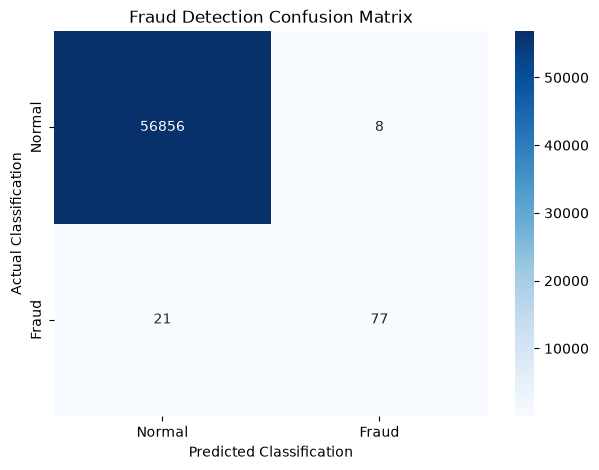

In [12]:
# STAGE 20: VISUALIZE MODEL PERFORMANCE

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Create the chart
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title("Fraud Detection Confusion Matrix")
plt.xlabel("Predicted Classification")
plt.ylabel("Actual Classification")

plt.show()

In [13]:
# STAGE 21: MULTIPLE TRANSACTION DEMONSTRATION

# Select 5 normal and 5 fraudulent transactions
normal_samples = y_test[y_test == 0].sample(n=5, random_state=42)
fraud_samples = y_test[y_test == 1].sample(n=5, random_state=42)

# Combine the selected transactions
demo_indices = list(normal_samples.index) + list(fraud_samples.index)

demo_data = X_test.loc[demo_indices]

# Generate predictions and fraud probabilities
demo_predictions = model.predict(demo_data)
demo_probabilities = model.predict_proba(demo_data)[:, 1]

# Display results
demo_results = pd.DataFrame({
    "Actual": y_test.loc[demo_indices].map({
        0: "Normal",
        1: "Fraud"
    }).values,
    "Prediction": pd.Series(demo_predictions).map({
        0: "Normal",
        1: "Fraud"
    }).values,
    "Fraud Risk (%)": (demo_probabilities * 100).round(2)
})

demo_results["Correct Prediction"] = (
    demo_results["Actual"] == demo_results["Prediction"]
)

display(demo_results)

,Actual,Prediction,Fraud Risk (%),Correct Prediction
0,Normal,Normal,0.0,True
1,Normal,Normal,0.0,True
2,Normal,Normal,0.0,True
3,Normal,Normal,0.0,True
4,Normal,Normal,0.0,True
5,Fraud,Fraud,89.0,True
6,Fraud,Normal,23.0,False
7,Fraud,Normal,0.0,False
8,Fraud,Normal,50.0,False
9,Fraud,Fraud,100.0,True


TOP 10 FRAUD DETECTION FEATURES


,Feature,Importance
14,V14,0.191038
10,V10,0.106849
4,V4,0.105643
12,V12,0.097603
17,V17,0.090339
3,V3,0.065919
11,V11,0.046342
16,V16,0.044655
2,V2,0.038335
9,V9,0.025445


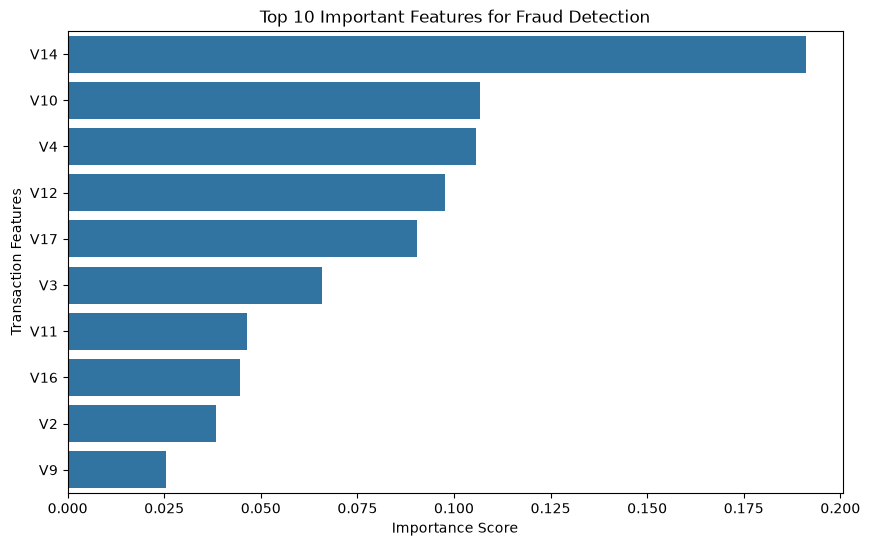

In [14]:
# STAGE 22: FEATURE IMPORTANCE ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importance from the trained model
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

# Arrange features from most important to least important
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 10 important features
print("TOP 10 FRAUD DETECTION FEATURES")
print("==============================")

display(importance.head(10))

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features for Fraud Detection")
plt.xlabel("Importance Score")
plt.ylabel("Transaction Features")

plt.show()

In [15]:
# STAGE 23: TEST THE SAVED MODEL

loaded_model = joblib.load("models/fraud_detection_model.pkl")

loaded_prediction = loaded_model.predict(fraud_transaction)[0]

print("SAVED MODEL TEST")
print("================")
print("Model loaded successfully!")

if loaded_prediction == 1:
    print("Prediction: FRAUDULENT TRANSACTION")
else:
    print("Prediction: NORMAL TRANSACTION")

SAVED MODEL TEST
Model loaded successfully!
Prediction: FRAUDULENT TRANSACTION


In [16]:
# STAGE 24: TEST NORMAL AND FRAUDULENT TRANSACTIONS

normal_prediction = loaded_model.predict(sample_transaction)[0]
fraud_prediction = loaded_model.predict(fraud_transaction)[0]

print("TRANSACTION TEST RESULTS")
print("========================")

print("Normal transaction test:")
print("Prediction:", "FRAUD" if normal_prediction == 1 else "NORMAL")

print("\nFraudulent transaction test:")
print("Prediction:", "FRAUD" if fraud_prediction == 1 else "NORMAL")

print("\nBoth transaction tests completed!")

TRANSACTION TEST RESULTS
Normal transaction test:
Prediction: NORMAL

Fraudulent transaction test:
Prediction: FRAUD

Both transaction tests completed!
